# Species Distribution Modeling: Rock pigeon (*Columba livia*) in South Korea

Sample notebook for the SDM web app. It follows the fairy pitta notebook (Crego et al. 2022 workflow, adapted from osgeokr's Earth Engine tutorial) with three differences:

1. **Different predictors.** The rock pigeon lives alongside people, so the candidates are climate, terrain, **population density, night-time light and NDVI** instead of tree canopy cover.
2. **Paginated GBIF download**, because common species have far more than one page of records.
3. **The final cell exports the model so the app can use it with no code changes:** it saves the image at `.../assets/sdm/columba_livia` and records the variables the model used in a `variables` property.

**To add another species:** copy this notebook, edit the CONFIG cell and the predictor cell, run everything, then add a `Bird` row in Django. If you use a variable that isn't in `userinputhandler/variables.py`, add one entry there with the same key as the band name here.

## NEW BIRD CHECKLIST (read this before copying the notebook)

Copy this file to `notebooks/sdm_<genus>_<species>.ipynb`, then work down the list. Cells you must edit are marked **CHANGE ME**.

| # | Do this | Where |
|---|---|---|
| 1 | Set `SPECIES_NAME`, `COUNTRY`, `MIN_YEAR` | **CHANGE ME** cell titled *CONFIG* |
| 2 | Choose the candidate predictors. Band names must match keys in `userinputhandler/variables.py` | **CHANGE ME** cell under *Candidate predictors* |
| 3 | Pick the pseudo-absence method (`background` or `kmeans`) | **CHANGE ME** cell under *Pseudo-absence data* |
| 4 | Set `numiter = 3` while testing, `10` for the final model | **CHANGE ME** cell starting `split = 0.7` |
| 5 | Run everything. The export cells start tasks for the map **and** the saved training tables (Scenario mode). Do not move on until every task prints `COMPLETED` | last cells |
| 6 | Read the *Check the model against the app* cell. It lists any variable you must add to `variables.py` | just before the export |
| 7 | Add the species to the database (snippet at the end) | Django shell |
| 8 | Optional: add Filter presets for the species | `userinputhandler/defaults.py` (`SPECIES_PRESETS`) |
| 9 | Optional: add Scenario presets or new variables' shift ranges | `defaults.py` (`SCENARIOS`) and `variables.py` (`shift`) |

**You never edit** the header, panels, JavaScript, `views.py` or `urls.py` for a new bird. The notebook declares what the app needs: the export is saved under the species name and stamped with the list of predictors the model used, and the app builds its sliders from that.

Full explanation: *SDM App: Workflow, Structure, Styling and Change Log* (the guide document).

In [1]:
%pip install earthengine-api geemap geopandas statsmodels ipyleaflet matplotlib pandas requests python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Run me first

Initialize Earth Engine (authenticate once with `ee.Authenticate()` if needed).

In [2]:
import os
import ee
from dotenv import find_dotenv, load_dotenv

# The Earth Engine project id lives in the repo's .env file (git-ignored), never in the notebook.
load_dotenv(find_dotenv(usecwd=True))
PROJECT = os.environ["EE_PROJECT"]

# Trigger the authentication flow once if needed.
##ee.Authenticate()

ee.Initialize(project=PROJECT)

### CONFIG: the only cell that is species-specific (apart from the predictor list)

`SLUG` and `ASSET_ID` follow the convention the app expects: the scientific name in lower case with underscores, inside `assets/sdm/`.

In [3]:
# ===== CHANGE ME ===========================================================
SPECIES_NAME = "Columba livia"     # scientific name; must match the Bird row you add in Django
COUNTRY      = "KR"                # 2-letter GBIF country code for the study region
MIN_YEAR     = 2010                # ignore older records
# ===========================================================================
# (Study region is not a whole country? Replace the "country" filter in the GBIF function below
#  with GBIF's "geometry" filter: a WKT polygon, vertices in counter-clockwise order.)

# ---- Do not edit below: naming convention the app depends on ----
ASSET_ROOT = f"projects/{PROJECT}/assets/sdm"
SLUG       = "_".join(SPECIES_NAME.lower().split())     # "Columba livia" -> "columba_livia"
ASSET_ID   = f"{ASSET_ROOT}/{SLUG}"
print(ASSET_ID)

projects/coral-circlet-470010-n8/assets/sdm/columba_livia


In [4]:
# Import libraries
import geemap  #mapping 

import geemap.colormaps as cm
import pandas as pd, geopandas as gpd
import numpy as np, matplotlib.pyplot as plt  
import os, requests, math, random  # directory, API access 

from ipyleaflet import TileLayer
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Occurrence data from GBIF

GBIF returns at most 300 records per request, so this version pages through the results (up to `max_records`). The year filter is applied by GBIF itself.

In [5]:
import datetime

def get_gbif_species_data(species_name, country_code, min_year=2010, max_records=10000):
    """Download human-observation records from GBIF (all pages) as a DataFrame."""
    base_url = "https://api.gbif.org/v1/occurrence/search"
    page = 300                                     # GBIF's maximum page size
    rows, offset = [], 0
    this_year = datetime.date.today().year

    while offset < max_records:
        params = {
            "scientificName": species_name,
            "country": country_code,
            "hasCoordinate": "true",
            "basisOfRecord": "HUMAN_OBSERVATION",
            "year": f"{min_year},{this_year}",
            "limit": page,
            "offset": offset,
        }
        try:
            response = requests.get(base_url, params=params, timeout=60)
            response.raise_for_status()
        except requests.RequestException as e:
            print(f"Request failed at offset {offset}: {e}")
            break
        data = response.json()
        rows.extend(data.get("results", []))
        if data.get("endOfRecords", True):
            break
        offset += page

    if not rows:
        print("No data found for the given species and country code.")
        return pd.DataFrame()
    return pd.json_normalize(rows)

In [6]:
df = get_gbif_species_data(SPECIES_NAME, COUNTRY, MIN_YEAR)
print(len(df), "records")
df.head(5)

10200 records


,key,datasetKey,publishingOrgKey,datasetCategory,installationKey,hostingOrganizationKey,publishingCountry,protocol,lastCrawled,lastParsed,...,scientificNameID,http://unknown.org/taxonRankID,taxonRemarks,http://unknown.org/species,http://unknown.org/crawlerDwcaCacheTime,http://unknown.org/orphanEndpoint,distanceFromCentroidInMeters,identificationReferences,locationRemarks,eventRemarks
0,5938038410,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-13T15:36:28.771+00:00,2026-10-14T02:45:08.891+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5938102849,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-13T15:36:28.771+00:00,2026-10-14T02:19:58.296+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5938155592,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-13T15:36:28.771+00:00,2026-10-14T02:34:36.710+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5938269850,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-13T15:36:28.771+00:00,2026-10-14T02:03:00.640+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5938325762,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-13T15:36:28.771+00:00,2026-10-14T02:20:02.803+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Convert DataFrame to GeoDataFrame
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.decimalLongitude, df.decimalLatitude),
    crs="EPSG:4326"
)[["species", "year", "month", "geometry"]]
gdf.head(5)

,species,year,month,geometry
0,Columba livia,2026,1,POINT (127.09991 37.50859)
1,Columba livia,2026,1,POINT (127.0971 37.51211)
2,Columba livia,2026,1,POINT (127.03947 37.46932)
3,Columba livia,2026,1,POINT (126.92982 37.48264)
4,Columba livia,2026,1,POINT (126.9528 37.47961)


In [8]:
# Optional extra filtering (the rock pigeon is resident all year, so nothing is removed by month)
filtered_gdf = gdf.dropna(subset=["geometry"])
len(filtered_gdf)

10200

In [9]:
# Convert GeoDataFrame to Earth Engine object
data_raw = geemap.geopandas_to_ee(filtered_gdf)

In [10]:
# Spatial resolution setting (meters)
grain_size = 1000

Keep one occurrence per 1 km pixel to limit sampling bias. Pigeons are heavily over-reported around cities, so this matters more here than for a rare species.

In [11]:
def remove_duplicates(data, grain_size):
    # Select one occurrence record per pixel at the chosen spatial resolution
    random_raster = ee.Image.random().reproject("EPSG:4326", None, grain_size)
    rand_point_vals = random_raster.sampleRegions(
        collection=ee.FeatureCollection(data), geometries=True
    )
    return rand_point_vals.distinct("random")


data = remove_duplicates(data_raw, grain_size)

# Before selection and after selection
print("Original data size:", data_raw.size().getInfo())
print("Final data size:", data.size().getInfo())

Original data size: 10200
Final data size: 1689


### Area of interest

The bounding box of the occurrence points plus a 50 km buffer.

In [12]:
# Define the AOI
aoi = data.geometry().bounds().buffer(distance=50000, maxError=1000)

outline = ee.Image().byte().paint(featureCollection=aoi, color=1, width=3)

Map = geemap.Map(layout={"height": "400px", "width": "800px"})
Map.addLayer(outline, {"palette": "FF0000"}, "AOI")
Map.addLayer(data, {"color": "red"}, "Presence")
Map.centerObject(aoi, 6)
Map

Map(center=[35.78601263062978, 127.11610426154576], controls=(WidgetControl(options=['position', 'transparent_…

### Candidate predictors

**These band names are the keys used by the app** (`userinputhandler/variables.py`): `bio01`, `bio12`, `elevation`, `slope`, `popdens`, `ntl`, `ndvi`. Keep them identical.

| Band | Dataset | Why it might matter for the rock pigeon |
|---|---|---|
| `bio01` | WorldClim V1 BIO: annual mean temperature (x10) | thermal limits |
| `bio12` | WorldClim V1 BIO: annual precipitation | climate |
| `elevation`, `slope` | SRTM 30 m | cliffs and steep terrain, vs flat urban land |
| `popdens` | CIESIN GPWv4.11 population density, 2020 | synanthropic: tracks people |
| `ntl` | NOAA VIIRS monthly night-time light, 2020 median | built-up and lit areas |
| `ndvi` | MODIS MOD13A2 NDVI, 2020 median | green space vs dense urban |

The VIF step further down removes redundant variables, so the model may use fewer than these seven.

#### CHANGE ME: choosing predictors for a new bird

1. Pick candidate variables that make sense ecologically for the species.
2. Name every band with a key from the table below (the app's **catalog**, `userinputhandler/variables.py`).
3. If you want a variable that is **not** in the catalog, build it here under any new name, then add one entry for it in `variables.py` with the same key. The check cell before the export tells you which ones are missing.

| Catalog key | Meaning | Units in the app |
|---|---|---|
| `bio01` | Annual mean temperature (WorldClim) | °C |
| `bio09` | Mean temperature, driest quarter | °C |
| `bio12` | Annual precipitation | mm |
| `bio14` | Precipitation, driest month | mm |
| `elevation`, `slope` | SRTM terrain | m, ° |
| `TCC` | Tree canopy cover (GFCC) | % |
| `ndvi` | Greenness (MODIS NDVI, 2020) | 0 to 1 |
| `popdens` | Human population density (GPW, 2020) | people/km² |
| `ntl` | Night-time light (VIIRS, 2020) | nW/cm²/sr |

**Region limits.** SRTM terrain only covers about 56°S to 60°N. For a study area outside that, swap the terrain source and the ocean mask (`watermask` below *and* the land mask in `build_predictors` in `sdm_model.py`) for a global elevation dataset.

Units note: WorldClim V1 stores temperatures as °C x 10. The notebook keeps the raw values because the models are trained on them. The app converts them to °C for the sliders and converts back (`model_scale` in `variables.py`) when it re-scores in Scenario mode. Do not rescale bands here without updating `model_scale`.

In [13]:
bio     = ee.Image("WORLDCLIM/V1/BIO")
terrain = ee.Algorithms.Terrain(ee.Image("USGS/SRTMGL1_003"))

popdens = (ee.ImageCollection("CIESIN/GPWv411/GPW_Population_Density")
           .filterDate("2020-01-01", "2020-12-31")
           .select("population_density").median().rename("popdens"))

ntl = (ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMCFG")
       .filterDate("2020-01-01", "2020-12-31")
       .select("avg_rad").median().rename("ntl"))

ndvi = (ee.ImageCollection("MODIS/061/MOD13A2")
        .filterDate("2020-01-01", "2020-12-31")
        .select("NDVI").median().multiply(0.0001).rename("ndvi"))

# Combine into one multiband image
predictors = (
    bio.select(["bio01", "bio12"])
    .addBands(terrain.select(["elevation", "slope"]))
    .addBands([popdens, ntl, ndvi])
)

# Mask out ocean pixels and clip to the area of interest
watermask = terrain.select("elevation").gt(0)
predictors = predictors.updateMask(watermask).clip(aoi)
print(predictors.bandNames().getInfo())

['bio01', 'bio12', 'elevation', 'slope', 'popdens', 'ntl', 'ndvi']


### Multicollinearity: correlation heatmap and VIF selection

In [14]:
# Generate 5,000 random points
data_cor = predictors.sample(scale=grain_size, numPixels=5000, geometries=True)

# Extract predictor variable values
pvals = predictors.sampleRegions(collection=data_cor, scale=grain_size)

In [15]:
# Converting predictor values from Earth Engine to a DataFrame
pvals_df = geemap.ee_to_df(pvals, remove_geom=False)
pvals_df = pvals_df.drop(columns=["geo"], errors="ignore")
pvals_df.head(1)

,bio01,bio12,elevation,ndvi,ntl,popdens,slope
0,139,1213,33,0.4937,3.20375,59.793232,1


In [16]:
def plot_correlation_heatmap(dataframe, h_size=10, show_labels=False):
    # Calculate Spearman correlation coefficients
    correlation_matrix = dataframe.corr(method="spearman")

    # Create a heatmap
    plt.figure(figsize=(h_size, h_size-2))
    plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='nearest')

    # Optionally display values on the heatmap
    if show_labels:
        for i in range(correlation_matrix.shape[0]):
            for j in range(correlation_matrix.shape[1]):
                plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                         ha='center', va='center', color='white', fontsize=8)

    columns = dataframe.columns.tolist()
    plt.xticks(range(len(columns)), columns, rotation=90)
    plt.yticks(range(len(columns)), columns)
    plt.title("Variables Correlation Matrix")
    plt.colorbar(label="Spearman Correlation")
    plt.savefig('correlation_heatmap_plot.png')
    plt.show()

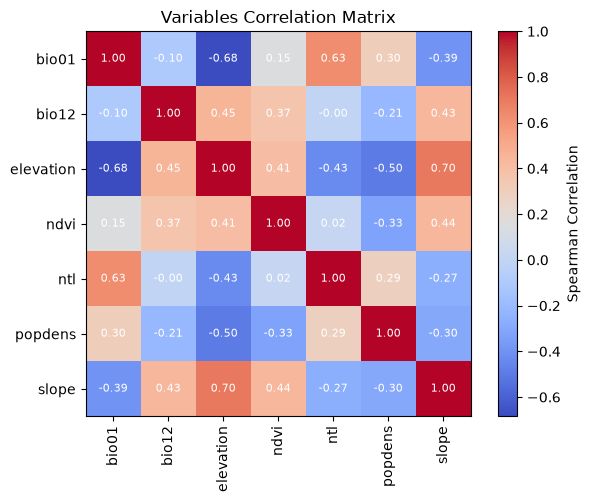

In [17]:
# Plot the correlation heatmap of variables
plot_correlation_heatmap(pvals_df, h_size=7, show_labels=True)

In [18]:
# Filter variables based on Variance Inflation Factor (VIF)
def filter_variables_by_vif(dataframe, threshold=10):

    original_columns = dataframe.columns.tolist()
    remaining_columns = original_columns[:]

    while True:
        vif_data = dataframe[remaining_columns]
        vif_values = [
            variance_inflation_factor(vif_data.values, i)
            for i in range(vif_data.shape[1])
        ]

        max_vif_index = vif_values.index(max(vif_values))
        max_vif = max(vif_values)

        if max_vif < threshold:
            break

        print(f"Removing '{remaining_columns[max_vif_index]}' with VIF {max_vif:.2f}")

        del remaining_columns[max_vif_index]

    filtered_data = dataframe[remaining_columns]
    bands = filtered_data.columns.tolist()
    print("Bands:", bands)

    return filtered_data, bands

In [19]:
filtered_pvals_df, bands = filter_variables_by_vif(pvals_df)

Bands: ['bio01', 'bio12', 'elevation', 'ndvi', 'ntl', 'popdens', 'slope']


Variables kept for the model: ['bio01', 'bio12', 'elevation', 'ndvi', 'ntl', 'popdens', 'slope']


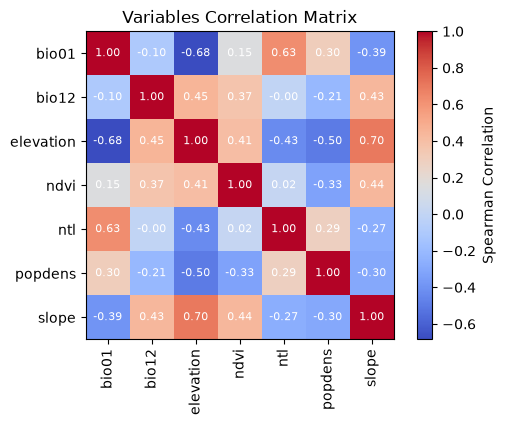

In [20]:
# Variable selection based on VIF. `bands` is what the app will be told to use.
predictors = predictors.select(bands)
print("Variables kept for the model:", bands)
plot_correlation_heatmap(filtered_pvals_df, h_size=6, show_labels=True)

### Pseudo-absence data

The model needs places where the species is *not* known to occur. There are two options (set `PA_METHOD` in the next cell):

* `"background"` (default for the rock pigeon): any land pixel with valid predictors that has no record. This suits a species that lives across the whole urban-to-rural gradient.
* `"kmeans"` (what the fairy pitta notebook used): only pixels in the cluster of environments *least similar* to the presence points. This can leave very little area, or area concentrated in a few places, and for a species that lives alongside people it picks exactly the places where the birds are. When too little of it falls inside a training block you get the `Only one class` error.

In [21]:
PA_METHOD = "background"      # "background" or "kmeans" (see the note above)

# Pixels where EVERY predictor has a value, so training points are never dropped later
valid = predictors.mask().reduce(ee.Reducer.min())

if PA_METHOD == "kmeans":
    # Randomly select 100 locations for occurrence
    pvals = predictors.sampleRegions(
        collection=data.randomColumn().sort('random').limit(100),
        properties=[],
        scale=grain_size
    )

    # Perform k-means clustering
    clusterer = ee.Clusterer.wekaKMeans(
        nClusters=2,
        distanceFunction="Euclidean"
    ).train(pvals)

    cl_result = predictors.cluster(clusterer)

    # Get cluster ID for locations similar to occurrence
    cl_id = cl_result.sampleRegions(
        collection=data.randomColumn().sort('random').limit(200),
        properties=[],
        scale=grain_size
    )

    # Define non-occurrence areas in dissimilar clusters
    cl_id = ee.FeatureCollection(cl_id).reduceColumns(ee.Reducer.mode(),['cluster'])
    cl_id = ee.Number(cl_id.get('mode')).subtract(1).abs()
    cl_mask = cl_result.select(['cluster']).eq(cl_id)
else:
    cl_mask = valid

In [22]:
# Presence location mask
presence_mask = data.reduceToImage(properties=['random'],
reducer=ee.Reducer.first()
).reproject('EPSG:4326', None,
            grain_size).mask().neq(1).selfMask()

# Masking presence locations in non-occurrence areas and clipping to AOI
area_for_pa = presence_mask.updateMask(cl_mask).clip(aoi)

# Area for Pseudo-absence
Map = geemap.Map(layout={'height':'400px', 'width':'800px'})
Map.addLayer(area_for_pa, {'palette': 'black'}, 'AreaForPA')
Map.centerObject(aoi, 6)
Map

Map(center=[35.78601263062977, 127.11610426154579], controls=(WidgetControl(options=['position', 'transparent_…

### Model fitting and prediction

Spatial block cross-validation with a 50 km grid, then 10 Random Forest runs. For a quick test set `numiter = 3` in the cell below.

In [23]:
# Block size (metres) for the spatial train/test split. 50 km suits a country-sized area.
# For a small region (fewer than ~10 blocks) use 20000 so every split has enough blocks.
Scale = 50000
grid = watermask.reduceRegions(
    collection=aoi.coveringGrid(scale=Scale, proj='EPSG:4326'),
    reducer=ee.Reducer.mean()).filter(ee.Filter.neq('mean', None))

Map = geemap.Map(layout={'height':'400px', 'width':'800px'})
Map.addLayer(grid, {}, "Grid for spatial block cross validation")
Map.addLayer(outline, {'palette': 'FF0000'}, "Study Area")
Map.centerObject(aoi, 6)
Map

Map(center=[35.78601263062977, 127.11610426154579], controls=(WidgetControl(options=['position', 'transparent_…

In [24]:
def sdm(x):
    seed = ee.Number(x)

    # Random block division for training and validation
    rand_blk = ee.FeatureCollection(grid).randomColumn(seed=seed).sort("random")
    training_grid = rand_blk.filter(ee.Filter.lt("random", split))  # Grid for training
    testing_grid = rand_blk.filter(ee.Filter.gte("random", split))  # Grid for testing

    # Presence points
    presence_points = ee.FeatureCollection(data)
    presence_points = presence_points.map(lambda feature: feature.set("PresAbs", 1))
    tr_presence_points = presence_points.filter(
        ee.Filter.bounds(training_grid)
    )  # Presence points for training
    te_presence_points = presence_points.filter(
        ee.Filter.bounds(testing_grid)
    )  # Presence points for testing

    # Pseudo-absence points for training
    tr_pseudo_abs_points = area_for_pa.sample(
        region=training_grid,
        scale=grain_size,
        numPixels=tr_presence_points.size().multiply(5).add(300),
        seed=seed,
        geometries=True,
    )
    # Same number of pseudo-absence points as presence points for training
    tr_pseudo_abs_points = (
        tr_pseudo_abs_points.randomColumn()
        .sort("random")
        .limit(ee.Number(tr_presence_points.size()))
    )
    tr_pseudo_abs_points = tr_pseudo_abs_points.map(lambda feature: feature.set("PresAbs", 0))

    te_pseudo_abs_points = area_for_pa.sample(
        region=testing_grid,
        scale=grain_size,
        numPixels=te_presence_points.size().multiply(5).add(100),
        seed=seed,
        geometries=True,
    )
    # Same number of pseudo-absence points as presence points for testing
    te_pseudo_abs_points = (
        te_pseudo_abs_points.randomColumn()
        .sort("random")
        .limit(ee.Number(te_presence_points.size()))
    )
    te_pseudo_abs_points = te_pseudo_abs_points.map(lambda feature: feature.set("PresAbs", 0))

    # Merge training and pseudo-absence points
    training_partition = tr_presence_points.merge(tr_pseudo_abs_points)
    testing_partition = te_presence_points.merge(te_pseudo_abs_points)

    # Extract predictor variable values at training points
    train_pvals = predictors.sampleRegions(
        collection=training_partition,
        properties=["PresAbs"],
        scale=grain_size,
        geometries=True,
    )

    # Random Forest classifier
    classifier = ee.Classifier.smileRandomForest(
        numberOfTrees=500,
        variablesPerSplit=None,
        minLeafPopulation=10,
        bagFraction=0.5,
        maxNodes=None,
        seed=seed,
    )
    # Presence probability: Habitat suitability map
    classifier_pr = classifier.setOutputMode("PROBABILITY").train(
        train_pvals, "PresAbs", bands
    )
    classified_img_pr = predictors.select(bands).classify(classifier_pr)

    # Binary presence/absence map: Potential distribution map
    classifier_bin = classifier.setOutputMode("CLASSIFICATION").train(
        train_pvals, "PresAbs", bands
    )
    classified_img_bin = predictors.select(bands).classify(classifier_bin)

    return [
        classified_img_pr,
        classified_img_bin,
        training_partition,
        testing_partition,
    ], classifier_bin

In [25]:
# ===== CHANGE ME =====
split = 0.7      # share of grid blocks used for training
numiter = 3      # 3 while testing; set to 10 for the final model
# ======================

# Random Seed
runif = lambda length: [random.randint(1, 1000) for _ in range(length)]
items = runif(numiter)

# Fixed seed
# items = [287, 288, 553, 226, 151, 255, 902, 267, 419, 538]

In [26]:
results_list = []       # SDM results
importances_list = []   # variable importance
used_seeds = []
trained_models = []      # the trained forests, saved later for Scenario mode

for item in items:
    try:
        result, trained = sdm(item)
        # Training only runs when we ask for a value, so any failure shows up on this line
        importance = ee.Dictionary(trained.explain()).get('importance').getInfo()
    except ee.EEException as e:
        print(f"seed {item} skipped: {e}")
        continue
    results_list.extend(result)
    importances_list.extend(importance.items())
    used_seeds.append(item)
    trained_models.append(trained)
    print(f"seed {item} done ({len(used_seeds)}/{len(items)})")

if not used_seeds:
    raise RuntimeError("Every run failed. Check the pseudo-absence area map and PA_METHOD.")

numiter = len(used_seeds)   # later cells use numiter, so it must match what succeeded
print("Runs completed:", numiter)

# Flatten the SDM results list
results = ee.List(results_list).flatten()

seed 106 skipped: Computation timed out.
seed 240 done (1/3)
seed 972 done (2/3)
Runs completed: 2


### Habitat suitability map

In [27]:
# Habitat suitability map
images = ee.List.sequence(
    0, ee.Number(numiter).multiply(4).subtract(1), 4).map(
    lambda x: results.get(x))
model_average = ee.ImageCollection.fromImages(images).mean()

Map = geemap.Map(layout={'height':'400px', 'width':'800px'}, basemap='Esri.WorldImagery')

vis_params = {
    'min': 0,
    'max': 1,
    'palette': cm.palettes.viridis_r}
Map.addLayer(model_average, vis_params, 'Habitat suitability')
Map.add_colorbar(vis_params, label="Habitat suitability",
                 orientation="horizontal",
                 layer_name="Habitat suitability")
Map.addLayer(data, {'color':'red'}, 'Presence')
Map.centerObject(aoi, 6)
Map

Map(center=[35.78601263062977, 127.11610426154579], controls=(WidgetControl(options=['position', 'transparent_…

### Variable importance

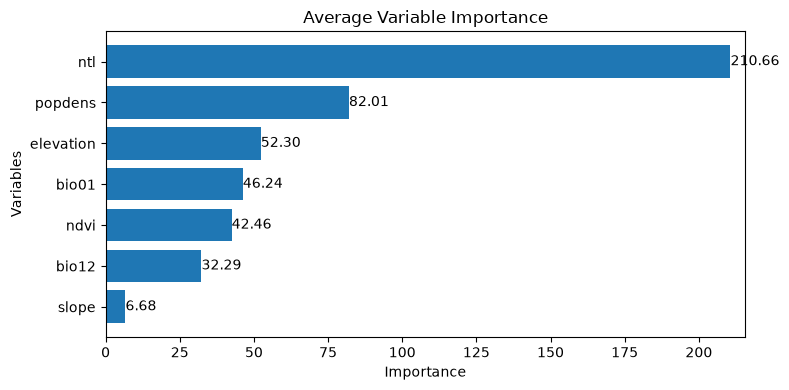

In [28]:
def plot_variable_importance(importances_list):
    # Extract each variable importance value into a list
    variables = [item[0] for item in importances_list]
    importances = [item[1] for item in importances_list]

    # Calculate the average importance for each variable
    average_importances = {}
    for variable in set(variables):
        indices = [i for i, var in enumerate(variables) if var == variable]
        average_importance = np.mean([importances[i] for i in indices])
        average_importances[variable] = average_importance

    # Sort the importances in descending order of importance
    sorted_importances = sorted(average_importances.items(),
                                key=lambda x: x[1], reverse=False)
    variables = [item[0] for item in sorted_importances]
    avg_importances = [item[1] for item in sorted_importances]

    # Adjust the graph size
    plt.figure(figsize=(8, 4))

    # Plot the average importance as a horizontal bar chart
    plt.barh(variables, avg_importances)
    plt.xlabel('Importance')
    plt.ylabel('Variables')
    plt.title('Average Variable Importance')

    # Display values above the bars
    for i, v in enumerate(avg_importances):
        plt.text(v + 0.02, i, f"{v:.2f}", va='center')

    # Adjust the x-axis range
    plt.xlim(0, max(avg_importances) + 5)  # Adjust to the desired range

    plt.tight_layout()
    plt.savefig('variable_importance.png')
    plt.show()

plot_variable_importance(importances_list)

### Accuracy assessment helpers

In [29]:
def print_pres_abs_sizes(TestingDatasets, numiter):
    # Check and print the sizes of presence and pseudo-absence coordinates
    def get_pres_abs_size(x):
        fc = ee.FeatureCollection(TestingDatasets.get(x))
        presence_size = fc.filter(ee.Filter.eq("PresAbs", 1)).size()
        pseudo_absence_size = fc.filter(ee.Filter.eq("PresAbs", 0)).size()
        return ee.List([presence_size, pseudo_absence_size])

    sizes_info = (
        ee.List.sequence(0, ee.Number(numiter).subtract(1), 1)
        .map(get_pres_abs_size)
        .getInfo()
    )

    for i, sizes in enumerate(sizes_info):
        presence_size = sizes[0]
        pseudo_absence_size = sizes[1]
        print(
            f"Iteration {i + 1}: Presence Size = {presence_size}, Pseudo-absence Size = {pseudo_absence_size}"
        )

In [30]:
# Extracting the Testing Datasets
testing_datasets = ee.List.sequence(
    3, ee.Number(numiter).multiply(4).subtract(1), 4
).map(lambda x: results.get(x))

print_pres_abs_sizes(testing_datasets, numiter)

Iteration 1: Presence Size = 417, Pseudo-absence Size = 417
Iteration 2: Presence Size = 556, Pseudo-absence Size = 556


In [31]:
def get_acc(hsm, t_data, grain_size):
    pr_prob_vals = hsm.sampleRegions(
        collection=t_data, properties=["PresAbs"], scale=grain_size
    )
    seq = ee.List.sequence(start=0, end=1, count=25)  # Divide 0 to 1 into 25 intervals

    def calculate_metrics(cutoff):
        # Each element of the seq list is passed as cutoff(threshold value)

        # Observed present = TP + FN
        pres = pr_prob_vals.filterMetadata("PresAbs", "equals", 1)

        # TP (True Positive)
        tp = ee.Number(
            pres.filterMetadata("classification", "greater_than", cutoff).size()
        )

        # TPR (True Positive Rate) = Recall = Sensitivity = TP / (TP + FN) = TP / Observed present
        tpr = tp.divide(pres.size())

        # Observed absent = FP + TN
        abs = pr_prob_vals.filterMetadata("PresAbs", "equals", 0)

        # FN (False Negative)
        fn = ee.Number(
            pres.filterMetadata("classification", "less_than", cutoff).size()
        )

        # TNR (True Negative Rate) = Specificity = TN  / (FP + TN) = TN / Observed absent
        tn = ee.Number(abs.filterMetadata("classification", "less_than", cutoff).size())
        tnr = tn.divide(abs.size())

        # FP (False Positive)
        fp = ee.Number(
            abs.filterMetadata("classification", "greater_than", cutoff).size()
        )

        # FPR (False Positive Rate) = FP / (FP + TN) = FP / Observed absent
        fpr = fp.divide(abs.size())

        # Precision = TP / (TP + FP) = TP / Predicted present
        precision = tp.divide(tp.add(fp))

        # SUMSS = SUM of Sensitivity and Specificity
        sumss = tpr.add(tnr)

        return ee.Feature(
            None,
            {
                "cutoff": cutoff,
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "TPR": tpr,
                "TNR": tnr,
                "FPR": fpr,
                "Precision": precision,
                "SUMSS": sumss,
            },
        )

    return ee.FeatureCollection(seq.map(calculate_metrics))

### Check the model against the app

The app can only draw a slider for variables listed in its catalog (`userinputhandler/variables.py`). This cell reads that file and compares it with the variables the model kept.

In [32]:
import re
from pathlib import Path

catalog_file = Path("../userinputhandler/variables.py")   # notebooks/ sits one level below the repo root
if not catalog_file.exists():
    print("Could not find", catalog_file.resolve(), "- run this notebook from the notebooks/ folder")
else:
    known = set(re.findall(r'^    "(\w+)":\s*\{', catalog_file.read_text(encoding="utf-8"), re.M))
    missing = [b for b in bands if b not in known]
    print("Variables the model used:", bands)
    if missing:
        print("\nNOT in the app catalog yet:", missing)
        print("Add one entry per missing variable to userinputhandler/variables.py (see the guide, section 1.4).")
    else:
        print("All variables are in the catalog. Safe to export.")

Variables the model used: ['bio01', 'bio12', 'elevation', 'ndvi', 'ntl', 'popdens', 'slope']
All variables are in the catalog. Safe to export.


### Export for the app

The map image is saved with properties the app reads:

* `species`: for reference only
* `variables`: the predictors the model actually used (comma-separated). The app builds its sliders from this, so **this is how a new species declares its variables**.
* `seeds`: the random seed of each run (comma-separated), so the app can rebuild the same forests.
* `n_models`: how many runs have saved training points for **Scenario mode** (next section). Without saved models the species still works in Filter mode.

Exports run on Google's servers. Do not move on until every task says `COMPLETED`. If `ASSET_ID` already exists the export fails, so delete the old one first (`ee.data.deleteAsset(ASSET_ID)`).

In [33]:
SAVE_MODELS = True     # True: also save the trained models so Scenario mode works. False: Filter mode only.

props = {
    "species": SPECIES_NAME,
    "variables": ",".join(bands),      # e.g. "bio01,popdens,ntl,ndvi"
    "seeds": ",".join(map(str, used_seeds)),   # the app needs these to rebuild the same forests
}
if SAVE_MODELS:
    props["n_models"] = len(trained_models)

final_image = model_average.toFloat().set(props)

task = ee.batch.Export.image.toAsset(
    image=final_image,
    description=SLUG,
    assetId=ASSET_ID,
    region=aoi,
    scale=1000,
    maxPixels=1e10,
)

try:
    ee.data.deleteAsset(ASSET_ID)
except ee.EEException:
    pass

task.start()
print(task.status())

{'state': 'READY', 'description': 'columba_livia', 'priority': 100, 'creation_timestamp_ms': 1792524621344, 'update_timestamp_ms': 1792524621344, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '6NGWE4VDBBRJWIF7TD7CXRWY', 'name': 'projects/coral-circlet-470010-n8/operations/6NGWE4VDBBRJWIF7TD7CXRWY'}


### Save the training data (for Scenario mode)

**Filter mode** only needs the finished map. **Scenario mode** re-scores every place with *changed* conditions (for example +2 °C), so the app needs the models. Earth Engine cannot export a Random Forest that gives probabilities (only 0/1 classes), and a loaded forest cannot be switched back to probability mode. So instead of the forests we save the **training points** of each run as `<species>__train_0`, `__train_1`, and so on, next to the map. The app retrains each forest from its points, using the seed stored in the map's `seeds` property, in probability mode. Retraining 500 trees on a few thousand points is quick, and the same points and seed give an equivalent forest.

**Units rule:** the app feeds these models the same bands in the same units they were trained on. Keep the notebook's predictor bands as they are (WorldClim temperature stays in degrees x 10). If you ever rescale a band here, set `model_scale` for it in `userinputhandler/variables.py`.

In [34]:
model_tasks = []
if SAVE_MODELS:
    for i in range(numiter):
        tid = f"{ASSET_ID}__train_{i}"
        try:
            ee.data.deleteAsset(tid)           # replace an earlier export
        except ee.EEException:
            pass                               # nothing to delete the first time
        fc = ee.FeatureCollection(results.get(i * 4 + 2))   # training_partition of run i
        t = ee.batch.Export.table.toAsset(
            collection=fc,
            description=f"{SLUG}_train_{i}",
            assetId=tid,
        )
        t.start()
        model_tasks.append(t)
    print(len(model_tasks), "training-table exports started")
else:
    print("SAVE_MODELS is False: Scenario mode will not be available for this species.")

2 training-table exports started


In [35]:
import time

all_tasks = [task] + model_tasks
while any(t.active() for t in all_tasks):
    print("running...", [t.status()["state"] for t in all_tasks])
    time.sleep(30)

for t in all_tasks:
    s = t.status()
    print(s["description"], s["state"], s.get("error_message", ""))

running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'RUNNING', 'READY']
running... ['RUNNING', 'COMPLETED', 'RUNNING']
running... ['COMPLETED', 'COMPLETED', 'RUNNING']
running... ['COMPLETED', 'COMPLETED', 'RUNNING']
running... ['COMPLETED', 'COMPLETED', 'RUNNING']
running... ['COMPLETED', 'COMPLETED', 'RUNNING']
running... ['COMPLETED', 'COMPLETED', 'RUNNING']
columba_livia COMPLETED 
columba_livia_train_0 COMPLETED 
columba_livia_train_1 COMPLETED 


In [36]:
# Check what was saved
info = ee.data.getAsset(ASSET_ID)
print(info["properties"])

if SAVE_MODELS:
    # Sanity check for Scenario mode: rebuild each forest from its SAVED training points
    # (in probability mode) and re-score today's conditions. The mean should be close to the
    # saved map's mean. If it is wildly different, tell whoever maintains the app.
    def load_model(i):
        pts = ee.FeatureCollection(f"{ASSET_ID}__train_{i}")
        tr = predictors.select(bands).sampleRegions(
            collection=pts, properties=["PresAbs"], scale=grain_size, geometries=True)
        return (ee.Classifier.smileRandomForest(
                    numberOfTrees=500, variablesPerSplit=None, minLeafPopulation=10,
                    bagFraction=0.5, maxNodes=None, seed=used_seeds[i])
                .setOutputMode("PROBABILITY")
                .train(tr, "PresAbs", bands))

    loaded = [load_model(i) for i in range(numiter)]
    rescored = ee.ImageCollection.fromImages(
        [predictors.select(bands).classify(c) for c in loaded]).mean()
    check = ee.Image.cat([rescored.rename("rescored"), ee.Image(ASSET_ID).rename("saved_map")])
    print(check.reduceRegion(reducer=ee.Reducer.mean(), geometry=aoi, scale=5000,
                             maxPixels=1e10, bestEffort=True).getInfo())

{'variables': 'bio01,bio12,elevation,ndvi,ntl,popdens,slope', 'species': 'Columba livia', 'seeds': '240,972', 'n_models': 2}
{'rescored': 0.22380605633621323, 'saved_map': 0.20826716325272365}


**Next steps in Django**

```python
# python manage.py shell
from userinputhandler.models import Bird
Bird.objects.get_or_create(scientific_name="Columba livia", defaults={"common_name": "Rock pigeon"})
```

Then reload the app, search "pigeon", and pick it.

**Optional: presets for this species.** Open `userinputhandler/defaults.py` and add an entry under `SPECIES_PRESETS`. The key is the asset name (`columba_livia`), and each preset is a set of fractions of each slider's range. A species with no entry there falls back to the generic `PRESETS`, which only mention the fairy pitta's variables.

**If you re-export the same species:** delete the old asset first (`ee.data.deleteAsset(ASSET_ID)`), run the export, wait for `COMPLETED`, then restart `runserver` so cached slider ranges are recalculated.

**Scenario mode** needs the saved training tables (`__train_i`) and the `seeds` property. If the app says a species has none, set `SAVE_MODELS = True`, run the training-table cells, and wait for `COMPLETED`. The fairy pitta has no saved models yet because it was exported before this step existed.